# Week 03: Visualization Practice (matplotlib and seaborn)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()     # a cleaner default look for every plot

df = pd.read_csv("../../Week-02/data/cleaned/car_details_cleaned.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (6699, 14)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine_cc,max_power_bhp,seats,mileage_unit,brand
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248,74.00,5,kmpl,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498,103.52,5,kmpl,Skoda
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497,78.00,5,kmpl,Honda
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396,90.00,5,kmpl,Hyundai
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298,88.20,5,kmpl,Maruti


Line Chart: change over time

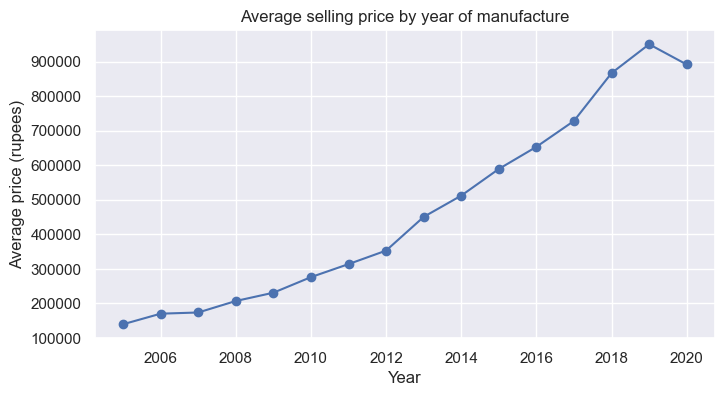

In [2]:
recent = df[df["year"] >= 2005]
avg_price = recent.groupby("year")["selling_price"].mean()

plt.figure(figsize=(8, 4))
plt.plot(avg_price.index, avg_price.values, marker="o")
plt.title("Average selling price by year of manufacture")
plt.xlabel("Year")
plt.ylabel("Average price (rupees)")
plt.show()

Histogram: how a number is spread out

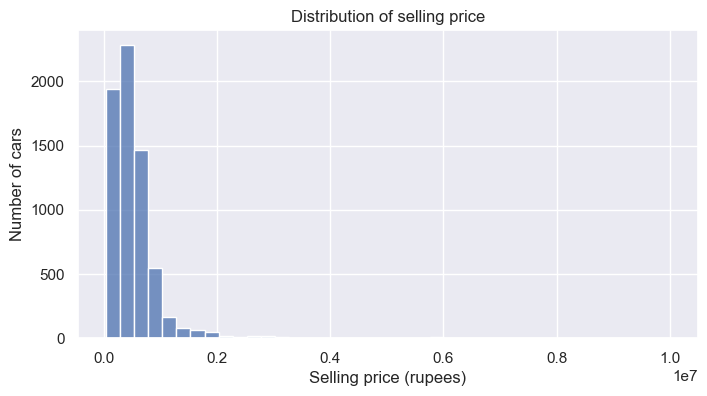

In [4]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="selling_price", bins=40)
plt.title("Distribution of selling price")
plt.xlabel("Selling price (rupees)")
plt.ylabel("Number of cars")
plt.show()

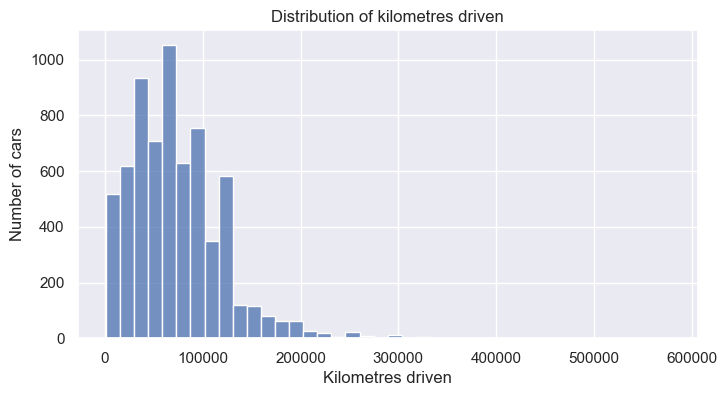

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="km_driven", bins=40)
plt.title("Distribution of kilometres driven")
plt.xlabel("Kilometres driven")
plt.ylabel("Number of cars")
plt.show()

Boxplot: compare groups and find outliers

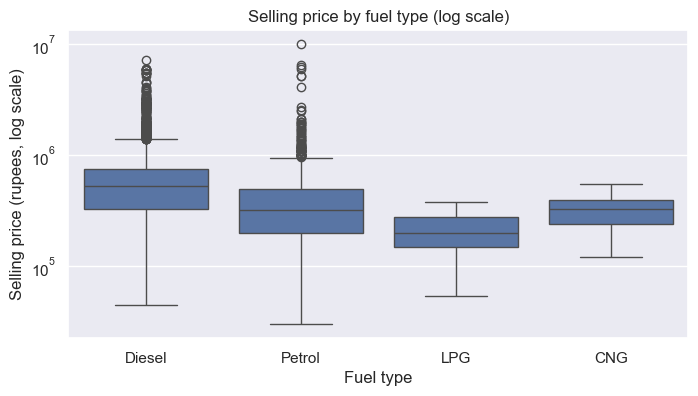

In [6]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="fuel", y="selling_price")
plt.yscale("log")     # prices are very spread out, so use a log scale to see all boxes clearly
plt.title("Selling price by fuel type (log scale)")
plt.xlabel("Fuel type")
plt.ylabel("Selling price (rupees, log scale)")
plt.show()

Scatter Plot: are two numbers related?

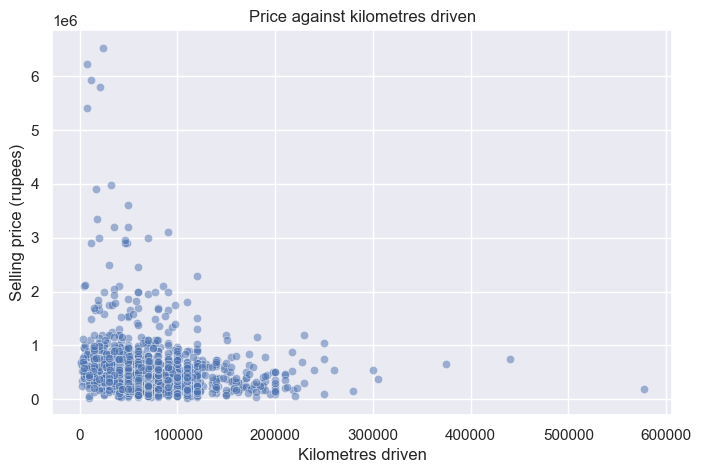

In [13]:
sample = df.sample(1500, random_state=1)     # 1500 random cars, so the plot is not too crowded

plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="km_driven", y="selling_price", alpha=0.5)
plt.title("Price against kilometres driven")
plt.xlabel("Kilometres driven")
plt.ylabel("Selling price (rupees)")
plt.show()

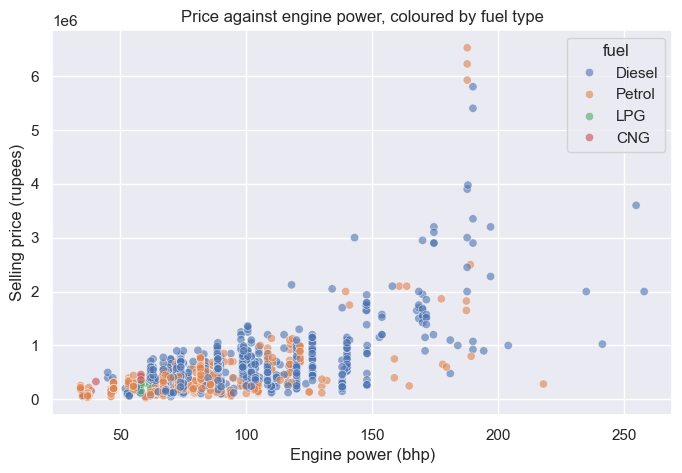

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="max_power_bhp", y="selling_price", hue="fuel", alpha=0.6)
plt.title("Price against engine power, coloured by fuel type")
plt.xlabel("Engine power (bhp)")
plt.ylabel("Selling price (rupees)")
plt.show()

Bar Chart: how many in each category

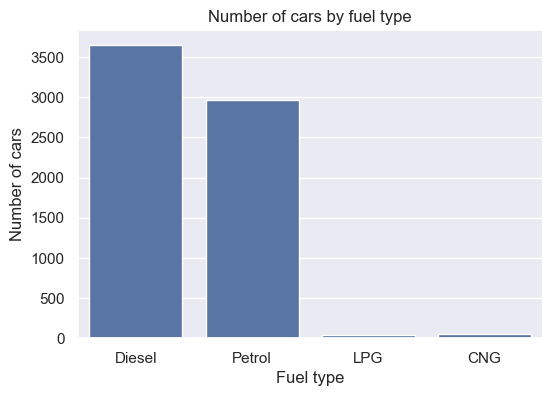

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="fuel")
plt.title("Number of cars by fuel type")
plt.xlabel("Fuel type")
plt.ylabel("Number of cars")
plt.show()

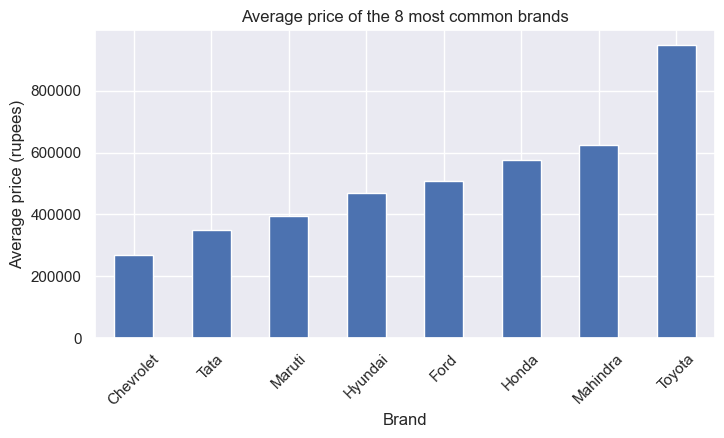

In [16]:
top_brands = df["brand"].value_counts().head(8).index
avg_by_brand = (df[df["brand"].isin(top_brands)]
                  .groupby("brand")["selling_price"].mean()
                  .sort_values())

plt.figure(figsize=(8, 4))
avg_by_brand.plot(kind="bar")
plt.title("Average price of the 8 most common brands")
plt.xlabel("Brand")
plt.ylabel("Average price (rupees)")
plt.xticks(rotation=45)
plt.show()

Heatmap: how several numbers relate

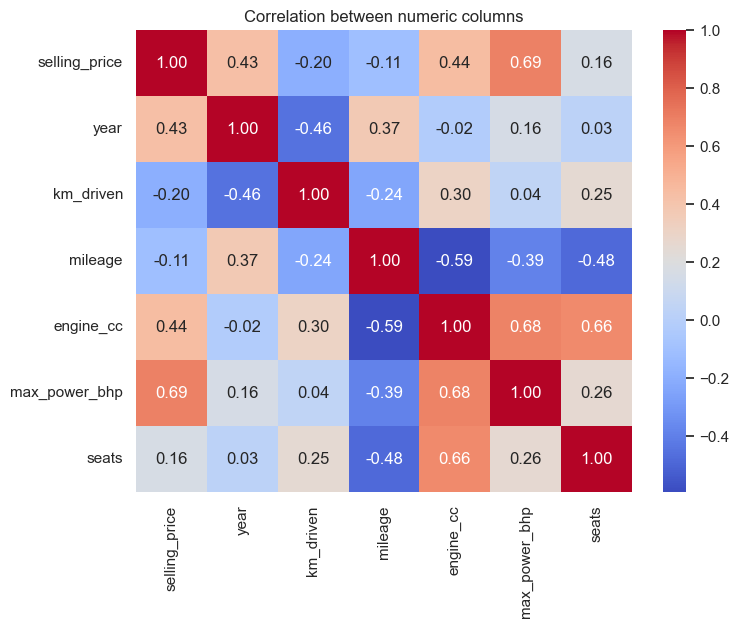

In [17]:
numbers = ["selling_price", "year", "km_driven", "mileage", "engine_cc", "max_power_bhp", "seats"]
corr = df[numbers].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between numeric columns")
plt.show()